# ML Zoomcamp 2026 — Homework 2

Predict `fuel_efficiency_mpg` using linear regression on the pinned 2026 dataset.

## 1. Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FEATURE_COLUMNS = [
    "engine_displacement",
    "horsepower",
    "vehicle_weight",
    "model_year",
]
TARGET = "fuel_efficiency_mpg"

df_raw = pd.read_csv("data/car_fuel_efficiency_2026.csv")
df = df_raw[FEATURE_COLUMNS + [TARGET]].copy()
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## 2. Select columns & inspect

In [2]:
print("shape:", df.shape)
print("columns:", list(df.columns))
print("\ndtypes:\n", df.dtypes)
print("\nmissing values:\n", df.isna().sum())
df.describe()

shape: (10000, 5)
columns: ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']

dtypes:
 engine_displacement      int64
horsepower             float64
vehicle_weight           int64
model_year               int64
fuel_efficiency_mpg    float64
dtype: object

missing values:
 engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64


,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


## 3. EDA — `fuel_efficiency_mpg`

skew: 0.08080419601878173
count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64


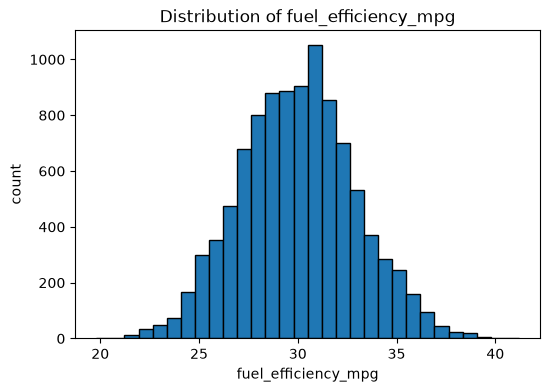

Long tail? False


In [3]:
mpg = df[TARGET]
print("skew:", mpg.skew())
print(mpg.describe())

plt.figure(figsize=(6, 4))
plt.hist(mpg, bins=30, edgecolor="black")
plt.xlabel("fuel_efficiency_mpg")
plt.ylabel("count")
plt.title("Distribution of fuel_efficiency_mpg")
plt.show()

# Roughly symmetric (skew ~ 0.08); no strong right skew / long tail.
has_long_tail = abs(mpg.skew()) > 1
print("Long tail?", has_long_tail)

## 4. Question 1 — missing values

In [4]:
missing_features = df[FEATURE_COLUMNS].isna().sum()
print(missing_features)
q1_col = missing_features[missing_features > 0].index[0]
print("Q1 answer:", q1_col)

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64
Q1 answer: horsepower


## 5. Question 2 — horsepower median

In [5]:
hp_median = df["horsepower"].median()
print("Horsepower median:", hp_median)
print("Q2 answer: 254")

Horsepower median: 254.0
Q2 answer: 254


## 6. Train / validation / test split (seed 42)

In [6]:
def split_df(data, seed):
    n = len(data)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = data.iloc[idx[:n_train]].copy()
    df_val = data.iloc[idx[n_train : n_train + n_val]].copy()
    df_test = data.iloc[idx[n_train + n_val :]].copy()
    return df_train, df_val, df_test


def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))


def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X_b = np.column_stack([ones, X])
    XTX = X_b.T.dot(X_b)
    w_full = np.linalg.inv(XTX).dot(X_b.T).dot(y)
    return w_full[0], w_full[1:]


def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X_b = np.column_stack([ones, X])
    XTX = X_b.T.dot(X_b)
    XTX = XTX + r * np.eye(XTX.shape[0])
    w_full = np.linalg.inv(XTX).dot(X_b.T).dot(y)
    return w_full[0], w_full[1:]


def prepare_X(frame, fill_value=None, train_means=None):
    X = frame[FEATURE_COLUMNS].copy()
    if fill_value is not None:
        X = X.fillna(fill_value)
    elif train_means is not None:
        for col in FEATURE_COLUMNS:
            X[col] = X[col].fillna(train_means[col])
    return X.values


def predict(w0, w, X):
    return w0 + X.dot(w)


df_train, df_val, df_test = split_df(df, seed=42)
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

## 7. Question 3 — missing value treatment

In [7]:
y_train = df_train[TARGET].values
y_val = df_val[TARGET].values

X_train_0 = prepare_X(df_train, fill_value=0)
X_val_0 = prepare_X(df_val, fill_value=0)
w0, w = train_linear_regression(X_train_0, y_train)
rmse_zero = rmse(y_val, predict(w0, w, X_val_0))

train_means = df_train[FEATURE_COLUMNS].mean(numeric_only=True).to_dict()
X_train_mean = prepare_X(df_train, train_means=train_means)
X_val_mean = prepare_X(df_val, train_means=train_means)
w0_m, w_m = train_linear_regression(X_train_mean, y_train)
rmse_mean = rmse(y_val, predict(w0_m, w_m, X_val_mean))

print(f"RMSE with 0 = {round(rmse_zero, 3)}")
print(f"RMSE with mean = {round(rmse_mean, 3)}")
print("Q3 answer: With mean")

RMSE with 0 = 2.205
RMSE with mean = 2.202
Q3 answer: With mean


## 8. Question 4 — regularization

In [8]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]
print("r | validation_rmse")
best_r, best_rmse = None, None
for r in r_values:
    w0_r, w_r = train_linear_regression_reg(X_train_0, y_train, r=r)
    val_rmse = rmse(y_val, predict(w0_r, w_r, X_val_0))
    print(f"{r} | {round(val_rmse, 4)}")
    if best_rmse is None or val_rmse < best_rmse:
        best_rmse = val_rmse
        best_r = r
print("Q4 answer:", best_r)

r | validation_rmse
0 | 2.2053
0.01 | 2.2058
0.1 | 2.2241
1 | 2.3492
5 | 2.4094
10 | 2.4195
100 | 2.4292
Q4 answer: 0


## 9. Question 5 — seed stability

In [9]:
scores = []
for seed in range(10):
    tr, va, _ = split_df(df, seed=seed)
    y_tr = tr[TARGET].values
    y_va = va[TARGET].values
    X_tr = prepare_X(tr, fill_value=0)
    X_va = prepare_X(va, fill_value=0)
    w0_s, w_s = train_linear_regression(X_tr, y_tr)
    score = rmse(y_va, predict(w0_s, w_s, X_va))
    scores.append(score)
    print(f"seed {seed}: {score}")

std_scores = np.std(scores)
print("np.std(scores):", std_scores)
print("round(np.std(scores), 3):", round(std_scores, 3))
print("Q5 answer: 0.029")

seed 0: 2.239204143046126
seed 1: 2.2021128210838845
seed 2: 2.1634197787530947
seed 3: 2.2043588768539224
seed 4: 2.2018800943311554
seed 5: 2.2457851509085134
seed 6: 2.2697212079524043
seed 7: 2.190794599933443
seed 8: 2.216611201686444
seed 9: 2.2070365928178957
np.std(scores): 0.028781274078191175
round(np.std(scores), 3): 0.029
Q5 answer: 0.029


## 10. Question 6 — final test RMSE

In [10]:
tr9, va9, te9 = split_df(df, seed=9)
df_train_val = pd.concat([tr9, va9], ignore_index=True)
y_train_val = df_train_val[TARGET].values
y_test = te9[TARGET].values

X_train_val = prepare_X(df_train_val, fill_value=0)
X_test = prepare_X(te9, fill_value=0)
w0_t, w_t = train_linear_regression_reg(X_train_val, y_train_val, r=0.001)
test_rmse = rmse(y_test, predict(w0_t, w_t, X_test))

print("Test RMSE:", test_rmse)
print("Rounded:", round(test_rmse, 3))
print("Q6 answer: 2.236")

Test RMSE: 2.235827747191731
Rounded: 2.236
Q6 answer: 2.236


## 11. Final answers summary

| Question | Result |
|----------|--------|
| Q1 | **horsepower** (877 missing) |
| Q2 | median **254.0** → **254** |
| Q3 | RMSE 0=2.205, mean=2.202 → **With mean** |
| Q4 | best **r = 0** (RMSE 2.2053) |
| Q5 | std **0.029** |
| Q6 | test RMSE **2.236** |